# 📖 Week 7 — Text and Multimodal AI
### *Project 2: Deep Learning Applications · Individual*
**Introduction to Applied AI · BS 8th Semester · Department of Electronics**

> **Theme of the day:** every component gets a number. *"It seems to extract names"* earns nothing;
> *"entity F1 rose from 0.53 to 0.88 on 16 gold entities"* is an engineering result.

| Part | Topic | Min | Output |
|:--:|---|:--:|---|
| 1 | TF-IDF by hand | 10 | Hand values == library values |
| 2 | Text classification: word vs char n-grams | 20 | macro-F1, top features, error analysis |
| 3 | NER: measure, then fix with rules | 20 | F1 before / after rules (provided + **own** gold set) |
| 4 | Regex fields with negative tests | 10 | Patterns that pass positive **and** negative tests |
| 5 | Character error rate and OCR repair | 10 | CER before / after correction |
| 6 | Image + text case record, with privacy | 20 | Masked, explainable JSON record |
| 7 | README + LinkedIn | async | Auto-filled from measured values |

**Dataset used this week:** 📨 *SMS Spam Collection Dataset* (`uciml/sms-spam-collection-dataset`) on Kaggle, plus your own `week6_model.pt`.

**How to use this notebook**
1. Pre-lab: Internet **On**, add the SMS Spam dataset, add your `week6-model` dataset.
2. Run top to bottom. Cells marked **✏️ EDIT** need *your* domain content.
3. After every part, fill in the **✍️ Write it** cell *in your own words, with numbers*.

## ⚙️ Setup
Imports, a fixed random seed, and a `RESULTS` dictionary. Every measured number is stored there so the README and LinkedIn post at the end fill themselves with **real** values.

In [6]:
import re, json, os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             precision_recall_fscore_support)

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25})

OUT = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
RESULTS = {}          # every measured value goes here -> README / LinkedIn

try:
    nlp = spacy.load('en_core_web_sm')          # preinstalled on Kaggle
except OSError:
    raise SystemExit("Run:  python -m spacy download en_core_web_sm   then restart.")
print('spaCy', spacy.__version__, '| output dir:', OUT)

spaCy 3.8.16 | output dir: /kaggle/working


---
# Part 1 · TF-IDF by Hand ⏱ 10 min
Before trusting a library, reproduce it. scikit-learn uses **smooth IDF**

$$\text{idf}(t)=\ln\frac{1+N}{1+\text{df}(t)}+1$$

then scales each document vector to **length 1** (L2 norm).

**Mini corpus:** `d1 = "win free cash now"`, `d2 = "call me now"`, `d3 = "free call now"`

In [7]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                      # smooth idf + L2 normalisation
X = vec.fit_transform(docs)
tfidf_table = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                           index=['d1', 'd2', 'd3']).round(3)
print('--- scikit-learn ---')
display(tfidf_table)

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win':  np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now':  np.log(4 / 4) + 1}
v = np.array(list(idf.values()))             # tf = 1 for each word in d1
by_hand = {w: round(float(x), 3) for w, x in zip(idf, v / np.linalg.norm(v))}
print('--- by hand (d1) ---')
print(by_hand)
print('Expected: win 0.584, free 0.445, cash 0.584, now 0.345')

--- scikit-learn ---


,call,cash,free,me,now,win
d1,0.000,0.584,0.445,0.00,0.345,0.584
d2,0.548,0.000,0.000,0.72,0.425,0.000
d3,0.620,0.000,0.620,0.00,0.481,0.000


--- by hand (d1) ---
{'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}
Expected: win 0.584, free 0.445, cash 0.584, now 0.345


idf(free) = ln(4/3) + 1 = 0.2877 + 1 = 1.2877   (df = 2)
idf(now)  = ln(4/4) + 1 = 0.0000 + 1 = 1.0000   (df = 3, appears everywhere)

Shared terms (term, d2, d3, product): [('call', 0.548, 0.62, 0.34), ('now', 0.425, 0.481, 0.205)]
cosine(d2, d3) = 0.544   (slide 10 says 0.54)


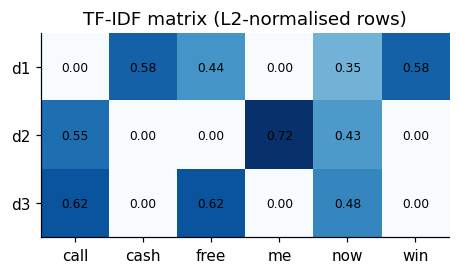

In [8]:
# The arithmetic you must show in your "Write it" cell
print(f"idf(free) = ln(4/3) + 1 = {np.log(4/3):.4f} + 1 = {np.log(4/3)+1:.4f}   (df = 2)")
print(f"idf(now)  = ln(4/4) + 1 = {np.log(4/4):.4f} + 1 = {np.log(4/4)+1:.4f}   (df = 3, appears everywhere)")

# Cosine similarity d2 vs d3 = dot product (vectors are already length 1)
d2, d3 = X.toarray()[1], X.toarray()[2]
cos_23 = float(d2 @ d3)
terms = vec.get_feature_names_out()
shared = [(t, round(float(a), 3), round(float(b), 3), round(float(a*b), 3))
          for t, a, b in zip(terms, d2, d3) if a > 0 and b > 0]
print('\nShared terms (term, d2, d3, product):', shared)
print(f'cosine(d2, d3) = {cos_23:.3f}   (slide 10 says 0.54)')
RESULTS['tfidf_cosine_d2_d3'] = round(cos_23, 3)

# Visual: a heatmap of the matrix
fig, ax = plt.subplots(figsize=(6, 2.6))
im = ax.imshow(X.toarray(), cmap='Blues')
ax.set_xticks(range(len(terms)), terms); ax.set_yticks(range(3), ['d1', 'd2', 'd3'])
for i in range(3):
    for j in range(len(terms)):
        ax.text(j, i, f'{X[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.grid(False); ax.set_title('TF-IDF matrix (L2-normalised rows)')
plt.tight_layout(); plt.show()

### ✍️ Write it — Part 1
> *Replace the dots with your own words and numbers.*

* **IDF arithmetic.** `idf(free) = ln(4/3)+1 = …` ; `idf(now) = ln(4/4)+1 = …`
* **Why does "now" get the lowest weight?** …
* **Cosine(d2, d3).** shared terms are … ; products … ; sum = … ; compare with **0.54** on slide 10 → …

---
# Part 2 · Text Classification: Word vs Character n-grams ⏱ 20 min
**Dataset:** SMS Spam Collection (`/kaggle/input/sms-spam-collection-dataset/spam.csv`).
It is **Latin-1 encoded** — keep `encoding='latin-1'`, otherwise you get a `UnicodeDecodeError`.

### Task 2.1 — Load and inspect
Accuracy is a trap on imbalanced data: a model that always says "ham" already scores ≈ 0.87, which is why we report **macro-F1**.

Found: ['/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv']
label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


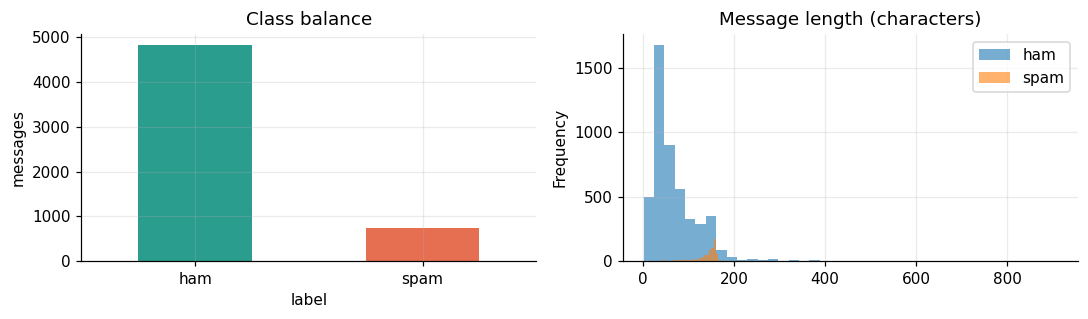

In [9]:
hits = glob.glob('/kaggle/input/**/spam.csv', recursive=True)   # works with any Kaggle folder layout
print('Found:', hits)
path = hits[0]
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   'always ham' accuracy: {1 - sms['y'].mean():.3f}")
RESULTS['sms_n'] = int(len(sms))
RESULTS['always_ham_acc'] = round(1 - sms['y'].mean(), 3)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sms['label'].value_counts().plot.bar(ax=ax[0], color=['#2a9d8f', '#e76f51'], rot=0)
ax[0].set_title('Class balance'); ax[0].set_ylabel('messages')
sms['text'].str.len().groupby(sms['label']).plot.hist(ax=ax[1], bins=40, alpha=.6, legend=True)
ax[1].set_title('Message length (characters)')
plt.tight_layout(); plt.show()

### Task 2.2 — Word n-gram classifier
Unigrams + bigrams, `min_df=2`, sub-linear TF (`1+log tf`), balanced class weights.

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



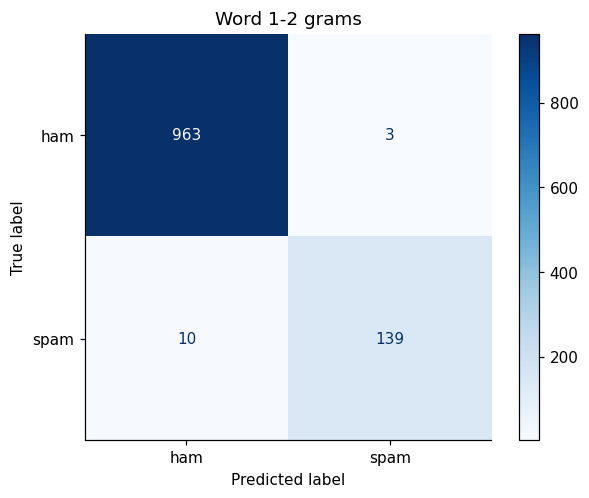

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=SEED, stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.title('Word 1-2 grams'); plt.grid(False); plt.show()

### Task 2.3 — What did it learn?
A classifier is only trustworthy if its **top features are sensible**. Look for shortcuts (e.g. a phone prefix or a formatting artefact that happens to correlate with spam in *this* dataset only).

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


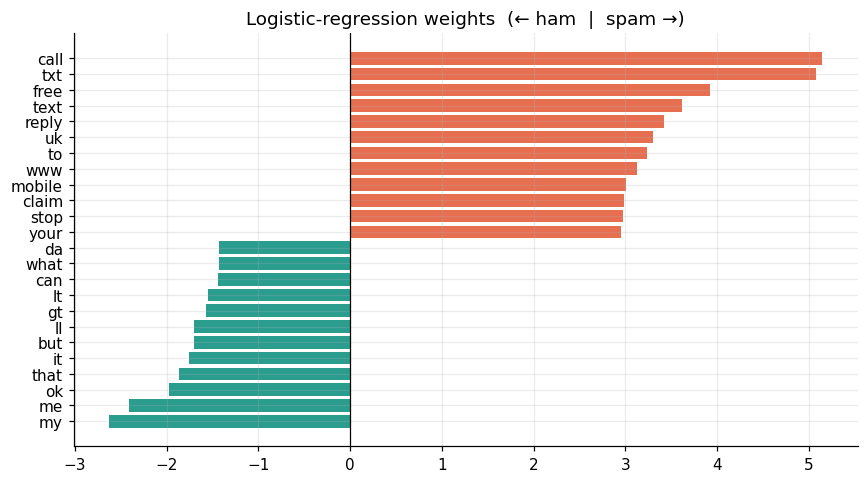

In [11]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
top_spam = list(terms[order[-12:]][::-1])
top_ham  = list(terms[order[:12]])
print('Most spam-like :', top_spam)
print('Most ham-like  :', top_ham)
RESULTS['top_spam'] = top_spam[:5]; RESULTS['top_ham'] = top_ham[:5]

fig, ax = plt.subplots(figsize=(8, 4.5))
idx = np.r_[order[:12], order[-12:]]
ax.barh([terms[i] for i in idx], w[idx],
        color=['#2a9d8f'] * 12 + ['#e76f51'] * 12)
ax.axvline(0, color='k', lw=.8)
ax.set_title('Logistic-regression weights  (← ham  |  spam →)')
plt.tight_layout(); plt.show()

### Task 2.4 — Character n-grams
`char_wb` n-grams (2–5) are robust to spelling tricks (`W1N`, `FR33`, Roman Urdu) because they never need to have seen the *exact word*.

,macro-F1,spam precision,spam recall,features
model,,,,
word 1-2 grams,0.974,0.979,0.933,12128
char 2-5 grams,0.982,0.986,0.953,36449


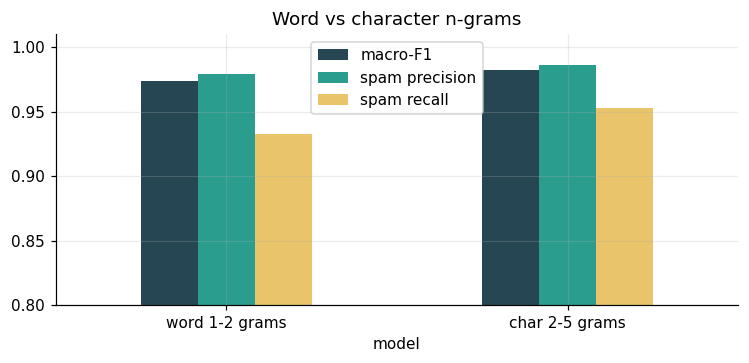

In [12]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

rows = []
for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    pr, rc, f1s, _ = precision_recall_fscore_support(y_te, p, labels=[1], zero_division=0)
    rows.append({'model': name,
                 'macro-F1': round(f1_score(y_te, p, average='macro'), 3),
                 'spam precision': round(float(pr[0]), 3),
                 'spam recall': round(float(rc[0]), 3),
                 'features': len(clf.named_steps['tfidf'].vocabulary_)})
cmp_df = pd.DataFrame(rows).set_index('model')
display(cmp_df)
RESULTS['word_macro_f1'] = float(cmp_df.loc['word 1-2 grams', 'macro-F1'])
RESULTS['char_macro_f1'] = float(cmp_df.loc['char 2-5 grams', 'macro-F1'])

cmp_df[['macro-F1', 'spam precision', 'spam recall']].plot.bar(rot=0, figsize=(7, 3.4),
        color=['#264653', '#2a9d8f', '#e9c46a'])
plt.ylim(.8, 1.01); plt.title('Word vs character n-grams'); plt.tight_layout(); plt.show()

In [13]:
# Robustness to spelling tricks.  The first two come from the lab.
# ✏️ EDIT: replace the last two with YOUR OWN tricky messages
#          (Roman Urdu, disguised spam, leetspeak, ...).
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now',
          'kal milte hain, 5 baje',
          'URGENT!! ur acc0unt is blkd, verify at b1t.ly/xyz now',      # ✏️ EDIT
          'Aap ka inaam nikla hai, abhi 8001 par SMS karein']           # ✏️ EDIT

tricky_df = pd.DataFrame({
    'message':        tricky,
    'P(spam) word':   word_clf.predict_proba(tricky)[:, 1].round(2),
    'P(spam) char':   char_clf.predict_proba(tricky)[:, 1].round(2)})
pd.set_option('display.max_colwidth', 70)
display(tricky_df)

,message,P(spam) word,P(spam) char
0,W1N a FR33 pr1ze!! txt CLAIM now,0.99,0.85
1,"kal milte hain, 5 baje",0.19,0.12
2,"URGENT!! ur acc0unt is blkd, verify at b1t.ly/xyz now",0.59,0.35
3,"Aap ka inaam nikla hai, abhi 8001 par SMS karein",0.44,0.28


### Task 2.5 — Error analysis
Every misclassified message is one of three things: a **model error**, a **label error** (the dataset is wrong), or **genuinely ambiguous**. Fill in the `your_verdict` column by reading each message.

In [14]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te.round(3)})
err = err[(err.p_spam >= 0.5) != (err.true == 1)].copy()
err['your_verdict'] = 'TODO: model error / label error / ambiguous'
pd.set_option('display.max_colwidth', 90)
print(f'{len(err)} misclassified of {len(X_te)}  '
      f'(false negatives: {(err.true == 1).sum()}, false positives: {(err.true == 0).sum()})')
display(err.sort_values('p_spam'))
RESULTS['word_errors'] = int(len(err))

13 misclassified of 1115  (false negatives: 10, false positives: 3)


,text,true,p_spam,your_verdict
750,"Do you realize that in about 40 years, we'll have thousands of old ladies running arou...",1,0.088,TODO: model error / label error / ambiguous
2246,Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodaf...,1,0.144,TODO: model error / label error / ambiguous
3979,ringtoneking 84484,1,0.192,TODO: model error / label error / ambiguous
1429,For sale - arsenal dartboard. Good condition but no doubles or trebles!,1,0.211,TODO: model error / label error / ambiguous
2821,ROMCAPspam Everyone around should be responding well to your presence since you are so...,1,0.252,TODO: model error / label error / ambiguous
3358,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,1,0.280,TODO: model error / label error / ambiguous
5449,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0.315,TODO: model error / label error / ambiguous
5,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun y...,1,0.412,TODO: model error / label error / ambiguous
2351,"Download as many ringtones as u like no restrictions, 1000s 2 choose. U can even send ...",1,0.425,TODO: model error / label error / ambiguous
1268,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum...,1,0.465,TODO: model error / label error / ambiguous


### ✍️ Write it — Part 2
> *Numbers required.*

| Model | macro-F1 | spam precision | spam recall |
|---|:--:|:--:|:--:|
| word 1–2 grams | … | … | … |
| char 2–5 grams | … | … | … |

* **Are the top features sensible, or shortcuts?** …
* **Misclassified messages:** n model errors = …, n label errors = …, n ambiguous = … (examples: …)
* **My two tricky messages:** `"…"` → word … / char … ; `"…"` → word … / char …
* **Which model would you ship, and why?** …

---
# Part 3 · Named Entity Recognition, Measured ⏱ 20 min
spaCy's small English model was trained on Western news. On Pakistani text, expect mistakes: *"Engro Fertilizers"* → `PERSON`, a date → `GPE`, a mobile number → `DATE`.

**Scoring rule:** an entity counts only if its **exact text AND label** match the gold set.

### Task 3.1 — Out of the box

In [15]:
sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']

for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Task 3.2 — Score against a gold set
The gold list is *what a careful human would mark*. 16 entities in total.

In [16]:
# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(nlp_model, sents=None, golds=None):
    """Exact-match entity precision / recall / F1 (text AND label)."""
    sents = sentences if sents is None else sents
    golds = gold if golds is None else golds
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f, 3),
            'tp': tp, 'fp': fp, 'fn': fn}

def show_errors(nlp_model, sents=None, golds=None):
    """Which entities are wrong (FP) or missing (FN)?  Needed for your analysis."""
    sents = sentences if sents is None else sents
    golds = gold if golds is None else golds
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        if pred != g:
            print('•', s)
            if pred - g: print('    wrong  :', sorted(pred - g))
            if g - pred: print('    missed :', sorted(g - pred))

base_scores = ner_scores(nlp)
print('spaCy out of the box:', base_scores)
print('Expected: precision 0.571, recall 0.500, F1 0.533')
RESULTS['ner_provided_before'] = base_scores['f1']
show_errors(nlp)

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533, 'tp': 8, 'fp': 6, 'fn': 8}
Expected: precision 0.571, recall 0.500, F1 0.533
• Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.
    wrong  : [('PIMS Islamabad', 'LOC')]
    missed : [('Islamabad', 'GPE'), ('PIMS', 'ORG')]
• The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.
    wrong  : [('30/09/2026', 'GPE'), ('Engro Fertilizers', 'PERSON')]
    missed : [('30/09/2026', 'DATE'), ('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY')]
• Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.
    wrong  : [('Farmer Muhammad Aslam', 'PERSON')]
    missed : [('Muhammad Aslam', 'PERSON')]
• Call Jazz support at 0300-1234567 or email help@jazz.com.pk.
    wrong  : [('0300-1234567', 'DATE')]
    missed : [('Jazz', 'ORG')]
• Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.
    wrong  : [('250,000', 'CARDINAL')]
    missed : [('Rs. 250,000', 'MONEY')]


### Task 3.3 — Add rules *before* the statistical model
An `entity_ruler` placed **before** `ner` wins on the spans it matches. We load a *fresh* pipeline each time, which avoids the classic `ValueError: entity_ruler already exists` when a cell is re-run.

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875, 'tp': 14, 'fp': 2, 'fn': 2}    (expected F1 0.875)
• Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.
    missed : [('Islamabad', 'GPE')]
• Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.
    wrong  : [('Farmer Muhammad Aslam', 'PERSON')]
    missed : [('Muhammad Aslam', 'PERSON')]
• Call Jazz support at 0300-1234567 or email help@jazz.com.pk.
    wrong  : [('0300-1234567', 'DATE')]


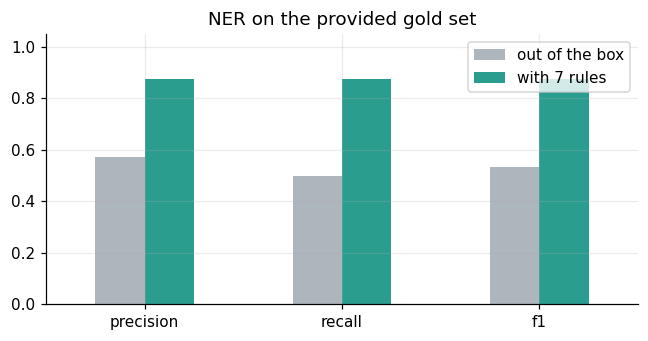

In [17]:
def build_nlp(patterns=None):
    """Fresh spaCy pipeline, optionally with an entity ruler before NER."""
    m = spacy.load('en_core_web_sm')
    if patterns:
        ruler = m.add_pipe('entity_ruler', before='ner')
        ruler.add_patterns(patterns)
    return m

PROVIDED_RULES = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
]
nlp_rules = build_nlp(PROVIDED_RULES)
rule_scores = ner_scores(nlp_rules)
print('spaCy + entity ruler:', rule_scores, '   (expected F1 0.875)')
RESULTS['ner_provided_after'] = rule_scores['f1']
show_errors(nlp_rules)

pd.DataFrame({'out of the box': base_scores, 'with 7 rules': rule_scores}).loc[
    ['precision', 'recall', 'f1']].plot.bar(rot=0, figsize=(6, 3.2), color=['#adb5bd', '#2a9d8f'])
plt.ylim(0, 1.05); plt.title('NER on the provided gold set'); plt.tight_layout(); plt.show()

### ✏️ Now do it for **your** domain
1. Write **10 sentences** from your domain (names, places, organisations, dates, amounts).
2. Annotate each as a set of `(text, label)` — exactly like `gold`.
3. Write rules **only from sentences 1–5** (the *dev* set), then score on sentences **6–10** (the *held-out* set). This stops the result from being optimistic.

> The cell below checks that every annotated text really appears in its sentence, and stays quiet until you have 10 entries.

In [18]:
# ✏️ EDIT — replace with YOUR 10 domain sentences and gold annotations.
# Format example (delete once you have your own):
#   ('Dr. Sana Malik at Shifa Hospital examined the patient on 14 March 2026.',
#    {('Sana Malik', 'PERSON'), ('Shifa Hospital', 'ORG'), ('14 March 2026', 'DATE')}),
DOMAIN = [
    # (sentence, {(text, label), ...}),   x 10
]

# ✏️ EDIT — rules written from sentences 1-5 ONLY (spaCy EntityRuler patterns)
# Example formats:
#   {'label': 'ORG',   'pattern': 'Shifa Hospital'}
#   {'label': 'MONEY', 'pattern': [{'LOWER': 'rs.'}, {'LIKE_NUM': True}]}
DOMAIN_RULES = [
]

def check_domain(domain):
    problems = []
    for i, (s, g) in enumerate(domain, 1):
        for text, label in g:
            if text not in s:
                problems.append(f'sentence {i}: "{text}" not found in sentence')
    return problems

DOMAIN_READY = len(DOMAIN) >= 10 and not check_domain(DOMAIN)
if not DOMAIN_READY:
    print(f'⚠️  Fill DOMAIN with 10 annotated sentences (you have {len(DOMAIN)}).')
    for p in check_domain(DOMAIN): print('   ', p)
else:
    dev, held = DOMAIN[:5], DOMAIN[5:]
    dev_s,  dev_g  = [d[0] for d in dev],  [d[1] for d in dev]
    held_s, held_g = [d[0] for d in held], [d[1] for d in held]

    nlp_domain = build_nlp(PROVIDED_RULES + DOMAIN_RULES)
    tab = pd.DataFrame({
        'dev (1-5)  before':      ner_scores(nlp,        dev_s,  dev_g),
        'dev (1-5)  after':       ner_scores(nlp_domain, dev_s,  dev_g),
        'held-out (6-10) before': ner_scores(nlp,        held_s, held_g),
        'held-out (6-10) after':  ner_scores(nlp_domain, held_s, held_g)})
    display(tab)
    RESULTS['ner_domain_before'] = float(tab.loc['f1', 'held-out (6-10) before'])
    RESULTS['ner_domain_after']  = float(tab.loc['f1', 'held-out (6-10) after'])
    print('\nRemaining errors on the HELD-OUT sentences:')
    show_errors(nlp_domain, held_s, held_g)

⚠️  Fill DOMAIN with 10 annotated sentences (you have 0).


### ✍️ Write it — Part 3
* **Provided sentences:** F1 before = … → after = … (precision …, recall …)
* **My held-out sentences (6–10):** F1 before = … → after = … (n gold entities = …)
* **Errors that remain after the rules:** …
* **Would I fix them with more rules, a regex, or a model trained on my data? Why?** (think: how many *new* names will appear tomorrow? are the formats fixed or free-form?) …

---
# Part 4 · Regex Fields with Negative Tests ⏱ 10 min
A pattern is only useful if it matches the positives **and ignores the negatives**. Always write patterns as raw strings `r'...'`.

In [19]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
}

def extract_fields(text, patterns=None):
    out = {}
    for name, pat in (patterns or PATTERNS).items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# (text, fields that MUST be found, fields that MUST NOT be found)
tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', {'cnic', 'mobile'}, set()),
    ('Total Rs. 12,500.50 paid on 05/10/2026',       {'amount', 'date'}, set()),
    ('Invoice No. 4417 from info@engro.com.pk',      {'invoice', 'email'}, set()),
    ('Order 12345678901234 shipped',                 set(), {'cnic'}),     # NOT a CNIC
    ('Room 0300 on floor 3',                         set(), {'mobile'}),   # NOT a mobile
]

def run_tests(tests, patterns=None, verbose=True):
    passed = 0
    for text, must, must_not in tests:
        got = set(extract_fields(text, patterns))
        ok = must <= got and not (must_not & got)
        passed += ok
        if verbose:
            print(f"{'PASS' if ok else 'FAIL'}  {sorted(got)!s:32} <- {text}")
    print(f'\n{passed}/{len(tests)} tests passed')
    return passed == len(tests)

run_tests(tests)

PASS  ['cnic', 'mobile']               <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS  ['amount', 'date']               <- Total Rs. 12,500.50 paid on 05/10/2026
PASS  ['email', 'invoice']             <- Invoice No. 4417 from info@engro.com.pk
PASS  []                               <- Order 12345678901234 shipped
PASS  []                               <- Room 0300 on floor 3

5/5 tests passed


True

#### 🔧 Worked example: a pattern that matched *too much*
Without `\b` word boundaries a CNIC pattern fires **inside** a longer number. Anchors and exact counts fix it.

In [20]:
too_greedy = r'\d{5}-\d{7}-\d'            # no word boundaries
fixed      = r'\b\d{5}-\d{7}-\d\b'        # boundaries + exact counts
text = 'Ref 9912345-1234567-19 (not a CNIC)'
print('greedy :', re.findall(too_greedy, text))   # false positive inside a longer id
print('fixed  :', re.findall(fixed, text))        # correctly ignored

greedy : ['12345-1234567-1']
fixed  : []


### ✏️ Adapt to your domain
Add patterns for things in **your** data (lot numbers, part codes, plot numbers, lab values, patient IDs …) and **at least two negative tests**. The example below is a template — replace it.

In [21]:
# ✏️ EDIT — your domain patterns
DOMAIN_PATTERNS = {
    'lot':   r'\bLOT-\d{4}\b',                          # e.g. LOT-0457
    'temp':  r'\b\d{2,3}(?:\.\d)?\s?°?C\b',             # e.g. 38.5 C
}

# ✏️ EDIT — your positives and (>= 2) negatives
domain_tests = [
    ('Batch LOT-0457 stored at 38.5 C',   {'lot', 'temp'}, set()),
    ('Gate LOT-45 is closed',             set(),           {'lot'}),    # NEG: too few digits
    ('Page 2025 of 3C report',            set(),           {'lot'}),    # NEG: not a lot code
]
ok = run_tests(domain_tests, DOMAIN_PATTERNS)
RESULTS['regex_fields'] = list(PATTERNS) + list(DOMAIN_PATTERNS)
RESULTS['regex_negative_tests'] = sum(1 for t in tests + domain_tests if t[2])

PASS  ['lot', 'temp']                  <- Batch LOT-0457 stored at 38.5 C
PASS  []                               <- Gate LOT-45 is closed
PASS  []                               <- Page 2025 of 3C report

3/3 tests passed


### ✍️ Write it — Part 4
* **My domain patterns and test results:** …
* **A pattern that initially matched too much** and how I fixed it (word boundaries / exact counts / anchors): …

---
# Part 5 · Character Error Rate and OCR Repair ⏱ 10 min
$$\text{CER}=\frac{\text{substitutions}+\text{deletions}+\text{insertions}}{\text{length of reference}}$$

The numerator is the **Levenshtein edit distance**. OCR confuses look-alike glyphs (`O`↔`0`, `l`/`I`↔`1`), but only *inside numbers* is that confusion safe to repair, so the rules use **context**.

### Task 5.1 — CER and context rules

In [22]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)                   # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026',   'Due 3O/09/2O26')]
rows = []
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    rows.append({'reference': ref, 'OCR output': hyp, 'CER before': round(cer(ref, hyp), 3),
                 'after fix_ocr': fixed, 'CER after': round(cer(ref, fixed), 3)})
display(pd.DataFrame(rows))
print('Expected CER: 0.062, 0.059, 0.143 before  ->  0.000 after')

,reference,OCR output,CER before,after fix_ocr,CER after
0,Invoice No. 4417,Invoice N0. 4417,0.062,Invoice No. 4417,0.0
1,"Total: PKR 12,500","Total: PKR 12,5O0",0.059,"Total: PKR 12,500",0.0
2,Due 30/09/2026,Due 3O/09/2O26,0.143,Due 30/09/2026,0.0


Expected CER: 0.062, 0.059, 0.143 before  ->  0.000 after


### Task 5.2 — OCR on an invoice
A **synthetic** invoice is generated so everyone has the same test document. Whitespace is normalised first, so CER counts *character* errors, not line breaks. (EasyOCR needs **Internet On** the first time — ≈100 MB download.)

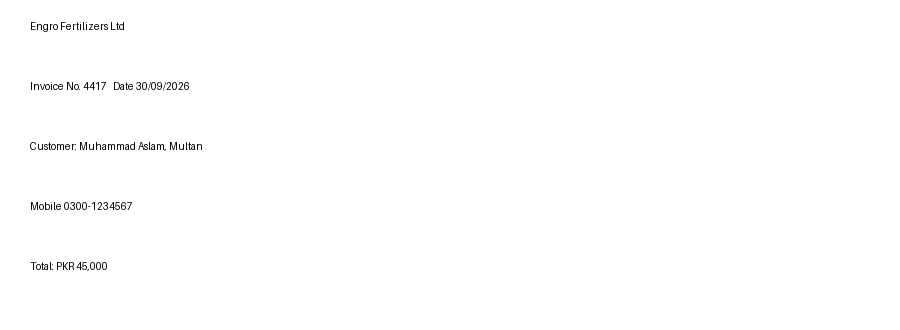

In [23]:
from PIL import Image, ImageDraw, ImageFont
import torch

lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']

def load_font(size=30):
    for p in ['/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
              '/usr/share/fonts/dejavu/DejaVuSans.ttf']:
        if os.path.exists(p):
            return ImageFont.truetype(p, size)
    return ImageFont.load_default()

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
font = load_font(30)
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')
display(img)

In [24]:
import easyocr
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))

norm  = lambda s: ' '.join(s.split())             # ignore line-break layout
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print('TRUTH:', truth)
print('OCR  :', raw)
cer_raw, cer_clean = cer(truth, raw), cer(truth, clean)
print(f'\nCER raw {cer_raw:.3f}   after fixes {cer_clean:.3f}')
RESULTS['cer_raw'] = round(cer_raw, 3); RESULTS['cer_after'] = round(cer_clean, 3)

# Where exactly are the remaining character errors?
import difflib
for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, truth, clean).get_opcodes():
    if tag != 'equal':
        print(f'  {tag:8s} truth[{i1}:{i2}]={truth[i1:i2]!r} -> ocr[{j1}:{j2}]={clean[j1:j2]!r}')

TRUTH: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
OCR  : Engro Fertilizers Ltd Invoice Na 4417 Date 30,09/2026 Customer: Muhammad Aslam Multan Mobile 0300-1234587 Total: PKR 45,000

CER raw 0.040   after fixes 0.040
  replace  truth[31:33]='o.' -> ocr[31:32]='a'
  replace  truth[46:47]='/' -> ocr[45:46]=','
  delete   truth[79:80]=',' -> ocr[78:78]=''
  replace  truth[105:106]='6' -> ocr[103:104]='8'


### ✍️ Write it — Part 5
* **CER raw = …, after correction = …**
* *(If the raw CER was already near zero)* why is this clean synthetic image easier than a real phone photo? (font, contrast, skew, blur, lighting, compression, handwriting …) …
* **What CER do I expect on my own documents, and which `fix_ocr` rules would I add?** …

---
# Part 6 · Image + Text Case Record, with Privacy ⏱ 20 min
We combine the **Week 6 image model** with **text evidence** into a single, explainable JSON record.

> 🔐 **Golden rule: mask personal identifiers BEFORE any entity or field extraction.** Otherwise the phone number reappears inside `text_evidence`.

### Task 6.1 — Mask personal identifiers

In [25]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'],   '[CNIC]',  text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'],  '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


### Task 6.2 — Load your Week 6 model and build evidence functions
`rebuild()` reconstructs your architecture from the checkpoint's saved settings and loads your trained weights, so **nothing is downloaded**.

If the checkpoint cannot be found, the notebook falls back to a clearly-labelled **DEMO MODE** (fixed fake probabilities) so you can still test the rest of the pipeline. *Demo-mode output is not a valid submission.*

In [26]:
import torch, torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import models, transforms

hits = glob.glob('/kaggle/input/**/week6_model.pt', recursive=True)   # works with any Kaggle folder layout
W6_PATH = hits[0] if hits else '/kaggle/input/week6-model/week6_model.pt'
DEMO_MODE = not os.path.exists(W6_PATH)
print('Week 6 model:', W6_PATH, '| DEMO_MODE =', DEMO_MODE)

if not DEMO_MODE:
    ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
    classes = ckpt['classes']
    GRAY = bool(ckpt.get('grayscale', False))
    print('Loaded checkpoint | backbone:', ckpt['backbone'], '| classes:', classes,
          '| img_size:', ckpt['img_size'], '| grayscale:', GRAY)

    def rebuild(ck):
        name, k = ck['backbone'], len(ck['classes'])
        if name.startswith('resnet'):
            m = getattr(models, name)(weights=None)
            m.fc = nn.Linear(m.fc.in_features, k)
        else:
            m = models.efficientnet_b0(weights=None)
            m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
        m.load_state_dict(ck['state_dict'])
        return m.eval()

    img_model = rebuild(ckpt)
    tf = transforms.Compose(
        ([transforms.Grayscale(3)] if GRAY else []) +
        [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    def image_evidence(path):
        x = tf(Image.open(path).convert('L' if GRAY else 'RGB'))
        with torch.no_grad():
            p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
        return {c: round(float(v), 3) for c, v in zip(classes, p)}
else:
    print('⚠️  DEMO MODE: week6_model.pt not found at', W6_PATH)
    classes = ['NORMAL', 'PNEUMONIA']                       # fake, for pipeline testing only
    def image_evidence(path):
        return {'NORMAL': 0.18, 'PNEUMONIA': 0.82}

Week 6 model: /kaggle/input/week6-model/week6_model.pt | DEMO_MODE = True
⚠️  DEMO MODE: week6_model.pt not found at /kaggle/input/week6-model/week6_model.pt


In [27]:
# ✏️ EDIT: warning terms from YOUR domain
URGENT = ['fever', 'breath', 'cough', 'chest pain', 'spreading', 'crack']

# The pipeline used for text evidence = spaCy + provided rules + YOUR domain rules
nlp_case = build_nlp(PROVIDED_RULES + (DOMAIN_RULES if 'DOMAIN_RULES' in globals() else []))

def text_evidence(note):
    doc = nlp_case(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

def fuse(p_image, p_text, w=0.5):
    """Weighted late fusion of two probabilities (see Check Your Understanding Q5)."""
    return w * p_image + (1 - w) * p_text

### Task 6.3 — One transparent record
Set `EXAMPLE_IMAGE` to a **test image from your Week 6 dataset**, and `POSITIVE` to the class you **must not miss**. Write a realistic note for your domain. Masking happens **first**.

In [28]:
EXAMPLE_IMAGE = '/kaggle/input/YOUR-WEEK6-DATASET/test/PNEUMONIA/example.jpeg'   # ✏️ EDIT
POSITIVE      = 'PNEUMONIA'                                                    # ✏️ EDIT

def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)                         # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'demo_mode': DEMO_MODE,
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

note = ('Child aged 4, fever for 3 days and fast breath. Seen at PIMS '      # ✏️ EDIT
        'Islamabad on 12/09/2026. Guardian mobile 0300-1234567.')
rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
print(json.dumps(rec, indent=2, ensure_ascii=False))

{
  "image": "example.jpeg",
  "demo_mode": true,
  "image_probabilities": {
    "NORMAL": 0.18,
    "PNEUMONIA": 0.82
  },
  "note_masked": "Child aged 4, fever for 3 days and fast breath. Seen at PIMS Islamabad on 12/09/2026. Guardian mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "4",
        "DATE"
      ],
      [
        "3 days",
        "DATE"
      ],
      [
        "PIMS",
        "ORG"
      ],
      [
        "12/09/2026",
        "DATE"
      ]
    ],
    "fields": {
      "date": [
        "12/09/2026"
      ]
    },
    "urgent_terms": [
      "fever",
      "breath"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(PNEUMONIA) = 0.82",
    "note mentions: fever, breath"
  ],
  "disclaimer": "Decision support only; a qualified human decides."
}


In [29]:
# 🔐 Privacy leak check: no digit of the phone / CNIC may appear anywhere in the JSON
SECRETS = ['0300-1234567', '03001234567', '1234567', '35202-1234567-1']   # ✏️ add yours
blob = json.dumps(rec, ensure_ascii=False)
leaks = [s for s in SECRETS if s in blob]
assert not leaks, f'PRIVACY LEAK: {leaks}'
print('✅ No identifiers found in the record.')
RESULTS['decision_example'] = rec['decision']

✅ No identifiers found in the record.


In [30]:
# 🧪 What happens when the image and the note DISAGREE?
cases = {
    'image high, note calm':   'Child comfortable, eating well, playing. No complaints.',
    'image high, note urgent': 'Child aged 4, fever for 3 days and fast breath.',
}
for label, n in cases.items():
    r = case_record(EXAMPLE_IMAGE, n, POSITIVE)
    print(f"{label:26s} -> {r['decision']:8s} reasons: {r['reasons']}")
print('\nFused example (Check Your Understanding Q5): ', fuse(0.30, 0.80, 0.5))

image high, note calm      -> REFER    reasons: ['image model: P(PNEUMONIA) = 0.82']
image high, note urgent    -> REFER    reasons: ['image model: P(PNEUMONIA) = 0.82', 'note mentions: fever, breath']

Fused example (Check Your Understanding Q5):  0.55


### ✍️ Write it — Part 6
* **My JSON record** *(paste the output above)*
* **Does each reason make sense?** …
* **One wrong entity in `text_evidence`** → `(text, label)` is wrong because … ; it is **harmless / harmful** here because …
* **A case where image and note disagree** (e.g. image says 0.2, note says "cannot breathe"): what should the system do? *(Think: which error is worse, a missed referral or an unnecessary one? Who decides?)* …

---
# 🧠 Check Your Understanding
Working for the calculations is shown by the cell below — **copy the steps into your own words** in the markdown cell that follows.

In [31]:
# Q1  smooth IDF: word in 9 of 1,000 docs
N_docs, df = 1000, 9
q1 = np.log((1 + N_docs) / (1 + df)) + 1
print(f'Q1  idf = ln(1001/10) + 1 = ln(100.1) + 1 = {np.log(100.1):.4f} + 1 = {q1:.3f}')

# Q3  precision / recall / F1
tp, predicted, gold_n = 6, 8, 10
P, R = tp / predicted, tp / gold_n
print(f'Q3  P = 6/8 = {P:.3f}   R = 6/10 = {R:.3f}   F1 = 2PR/(P+R) = {2*P*R/(P+R):.3f}')

# Q4  CER
ref, hyp = 'PKR 4,500', 'PKR 4,5OO'
print(f'Q4  edit distance = {levenshtein(ref, hyp)}, |ref| = {len(ref)}  ->  CER = {cer(ref, hyp):.3f}')

# Q5  fusion
print(f'Q5  fused = w*p_image + (1-w)*p_text = 0.5*0.30 + 0.5*0.80 = {0.5*0.30 + 0.5*0.80:.2f}')

Q1  idf = ln(1001/10) + 1 = ln(100.1) + 1 = 4.6062 + 1 = 5.606
Q3  P = 6/8 = 0.750   R = 6/10 = 0.600   F1 = 2PR/(P+R) = 0.667
Q4  edit distance = 2, |ref| = 9  ->  CER = 0.222
Q5  fused = w*p_image + (1-w)*p_text = 0.5*0.30 + 0.5*0.80 = 0.55


### ✍️ Answers *(your own words, with working)*
1. **Smooth IDF** of a word in 9 / 1,000 documents: `ln(1001/10) + 1 = …`
2. **Why can lowercasing hurt a spam classifier?** *(hint: think of `FREE`, `WIN`, `URGENT`, `CALL NOW`, and what capitalisation signals)* …
3. **Precision / recall / F1:** P = … ; R = … ; F1 = …
4. **CER** of `"PKR 4,5OO"` vs `"PKR 4,500"`: … errors / 9 = …
5. **Fused probability** (w = 0.5): …
6. **Why mask identifiers BEFORE entity and field extraction?** *(hint: where do the extracted values end up? what did the "bug we fixed" show?)* …

---
# Part 7 · README and LinkedIn *(async)*
This cell fills your README section and LinkedIn draft from the **values measured in this notebook**. Anything it could not measure stays as `[?]` — go back and run that part. *Replace every remaining bracket before you post.*

In [32]:
R = RESULTS
g = lambda k, d='[?]': R.get(k, d)

readme = f"""## Week 7: Text and Multimodal AI
- Text classifier: SMS Spam Collection, {g('sms_n')} texts, macro-F1 {g('word_macro_f1')} (word) vs {g('char_macro_f1')} (char)
- Top positive / negative features: {g('top_spam')} / {g('top_ham')}
- NER on my domain: out-of-the-box F1 {g('ner_domain_before')} -> with entity ruler {g('ner_domain_after')}
  (provided set: {g('ner_provided_before')} -> {g('ner_provided_after')})
- Regex fields extracted: {g('regex_fields')}; false positives tested: {g('regex_negative_tests')} negative tests
- OCR: CER raw {g('cer_raw')} -> after correction rules {g('cer_after')}
- Pipeline: image model + text evidence -> JSON record (example below)
- Privacy: CNIC, phone, and email masked before logging
"""

linkedin = f"""Week 7 of Applied AI: my model learned to read.

Out of the box, a popular NLP library called "Engro Fertilizers" a PERSON and "PKR 45,000" an organisation. Local context matters.

I measured it (NER F1 {g('ner_provided_before')}), added rules for Pakistani names, currency and dates (F1 {g('ner_provided_after')}), and fixed OCR errors like "N0. 4417" automatically.

Now my Week 6 image model and the text around it produce one structured record.
#NLP #spaCy #MultimodalAI #LearningInPublic"""

print(readme); print('-' * 60); print(linkedin)

with open(f'{OUT}/README_week7_section.md', 'w') as f:  f.write(readme)
with open(f'{OUT}/linkedin_post.txt', 'w') as f:        f.write(linkedin)
with open(f'{OUT}/results.json', 'w') as f:             json.dump(R, f, indent=2, default=str)
if 'rec' in globals():
    with open(f'{OUT}/case_record_example.json', 'w') as f:
        json.dump(rec, f, indent=2, ensure_ascii=False)
print(f'\nSaved README section, LinkedIn post, results.json and the case record to {OUT}')

## Week 7: Text and Multimodal AI
- Text classifier: SMS Spam Collection, 5572 texts, macro-F1 0.974 (word) vs 0.982 (char)
- Top positive / negative features: ['call', 'txt', 'free', 'text', 'reply'] / ['my', 'me', 'ok', 'that', 'it']
- NER on my domain: out-of-the-box F1 [?] -> with entity ruler [?]
  (provided set: 0.533 -> 0.875)
- Regex fields extracted: ['cnic', 'mobile', 'amount', 'date', 'email', 'invoice', 'lot', 'temp']; false positives tested: 4 negative tests
- OCR: CER raw 0.04 -> after correction rules 0.04
- Pipeline: image model + text evidence -> JSON record (example below)
- Privacy: CNIC, phone, and email masked before logging

------------------------------------------------------------
Week 7 of Applied AI: my model learned to read.

Out of the box, a popular NLP library called "Engro Fertilizers" a PERSON and "PKR 45,000" an organisation. Local context matters.

I measured it (NER F1 0.533), added rules for Pakistani names, currency and dates (F1 0.875), and fixed

---
### ✅ Deliverables checklist
- [ ] TF-IDF values reproduced; IDF arithmetic and one cosine shown
- [ ] Word and char classifiers: macro-F1, spam precision and recall
- [ ] Top features read; errors classified; two tricky messages tested
- [ ] NER F1 on the provided gold set, before and after rules
- [ ] Your own 10-sentence gold set; held-out F1 before and after
- [ ] Domain regex patterns with at least two negative tests
- [ ] CER before and after correction
- [ ] Masked JSON case record from your Week 6 model and a domain note
- [ ] A "Write it" markdown cell after every part
- [ ] Check Your Understanding answers
- [ ] README section and LinkedIn post

> **Integrity:** the provided sentences and dataset are shared, but your domain gold set, patterns, error analysis and written insights must be **your own**.

**Next week (Week 8):** serve your Project 2 model through a FastAPI endpoint → `pip install fastapi uvicorn`. Prepare a 2-minute Project 3 pitch: *who has the problem, how often, what it costs.*